<a href="https://colab.research.google.com/github/Rohit-Aroonslam/HCIA_Course/blob/main/HCIA_AI_Framwork_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning and AI Development Framework Lab 7.3
Use PyTorch to create and manipulate tensors, load datasets, and build three models: LeNet (CIFAR-10 images), ResNet-50 (flower images) and TextCNN (movie review sentiment).

In [1]:
#Check PyTorch and the GPU
import torch
print(torch.__version__, torch.cuda.is_available())

2.14.1+cu130 True


## 1.2 PyTorch Basics

### 1.2.1 Creating a tensor
Tensors of different dimensions hold different data: a 0-dimensional tensor is a scalar, 1-dimensional a vector, 2-dimensional a matrix, and 3-dimensional can hold the RGB channels of an image.


#### Step 1: Randomly initialize a tensor

In [2]:
import torch
x = torch.rand(4, 3)
print(x)

tensor([[0.9318, 0.4139, 0.9088],
        [0.8765, 0.0798, 0.4792],
        [0.8510, 0.3177, 0.2439],
        [0.3397, 0.0381, 0.6470]])


#### Step 2: Create a tensor from different types of data

In [3]:
import numpy as np
print(torch.Tensor(np.array([[1,2], [3,4]]))) #array
print(torch.Tensor([True, False])) #bool
print(torch.Tensor((1, 2, 3, 4, 5))) #tuple
print(torch.Tensor([i for i in range(10)])) #list

tensor([[1., 2.],
        [3., 4.]])
tensor([1., 0.])
tensor([1., 2., 3., 4., 5.])
tensor([0., 1., 2., 3., 4., 5., 6., 7., 8., 9.])


#### Step 3: Build different types of tensors:
Create 2 x 3 tensors of different data types and print each type.

In [4]:
print(torch.FloatTensor(2,3).type())    # float
print(torch.DoubleTensor(2,3).type())   # double
print(torch.HalfTensor(2,3).type())     # half
print(torch.ByteTensor(2,3).type())     # byte
print(torch.CharTensor(2,3).type())     # char
print(torch.ShortTensor(2,3).type())    # short
print(torch.IntTensor(2,3).type())      # int
print(torch.LongTensor(2,3).type())     # long

torch.FloatTensor
torch.DoubleTensor
torch.HalfTensor
torch.ByteTensor
torch.CharTensor
torch.ShortTensor
torch.IntTensor
torch.LongTensor


#### Step 4: Create special tensors:
All-zero, all-one and random tensors with a chosen data type.

In [5]:
x = torch.zeros(4, 3, dtype=torch.long)
print(x)                                       # all zeros
x = torch.ones(4, 3, dtype=torch.long)
print(x)                                       # all ones
x = x.new_ones(4, 3, dtype=torch.double)
print(x)                                       # all ones, double
x = torch.randn_like(x, dtype=torch.float)
print(x)                                       # random, same shape

tensor([[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]])
tensor([[1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]])
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]], dtype=torch.float64)
tensor([[ 0.4284,  0.5069,  1.5385],
        [ 0.2190, -0.5711, -0.4500],
        [-0.9518,  0.2767, -0.9782],
        [ 0.2393, -0.8275,  0.9619]])


### 1.2.2 Tensor attributes
The shape and the data type (dtype) are the main attributes of a tensor. The shape is a tuple, and the dtype is the PyTorch data type.

In [6]:
x = torch.Tensor(np.array([[1, 2], [3, 4]]))
print(x.shape)    # shape
print(x.size())   # size
print(x.dim())    # dimensions
print(x.device)   # hardware
print(x.dtype)    # data type

torch.Size([2, 2])
torch.Size([2, 2])
2
cpu
torch.float32


### 1.2.3 Tensor methods
Reshape a tensor, add or remove a dimension, flatten it to one dimension and move it to a device.

In [7]:
x = torch.Tensor(np.array([[1, 2], [3, 4]]))

print(x.reshape(4, 1))   # reshape
x = x.unsqueeze(2)       # add a dimension
print(x.shape)
x = x.squeeze(2)         # remove a dimension
print(x.shape)
print(x.flatten())       # flatten to one dimension

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
x = x.to(device)         # move to the device
print(x.device)

tensor([[1.],
        [2.],
        [3.],
        [4.]])
torch.Size([2, 2, 1])
torch.Size([2, 2])
tensor([1., 2., 3., 4.])
cuda:0


### 1.2.4 Loading the dataset


#### Step 1: Load the MNIST dataset
PyTorch downloads the MNIST handwritten digit images automatically if they are not already in the folder. Show the first three training images.

100%|██████████| 9.91M/9.91M [00:00<00:00, 15.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]


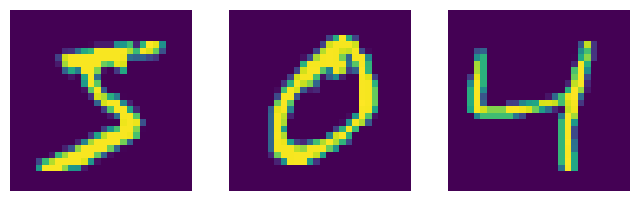

In [8]:
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Read images from the MNIST dataset
train_dataset = datasets.MNIST(root='./MNIST', train=True, download=True, transform=transforms.ToTensor())

# View the images
plt.figure(figsize=(8, 8))
i = 1
for dic in train_dataset.data[:3]:
    plt.subplot(3, 3, i)
    plt.imshow(dic)
    plt.axis('off')
    i += 1
plt.show()

#### Step 2: Use ImageFolder to load the dataset
The flower photos used in the ResNet experiment are loaded here. First download them.

In [9]:
!pip install download

In [10]:
from download import download

url_train = "https://ascend-professional-construction-dataset.obs.myhuaweicloud.com/deep-learning/flower_photos_train.zip"
url_test = "https://ascend-professional-construction-dataset.obs.myhuaweicloud.com/deep-learning/flower_photos_test.zip"

path_train = download(url_train, "./", kind="zip", replace=True, verbose=False)
path_test = download(url_test, "./", kind="zip", replace=True, verbose=False)

file_sizes: 100%|████████████████████████████| 227M/227M [00:51<00:00, 4.40MB/s]
file_sizes: 100%|██████████████████████████| 3.01M/3.01M [00:01<00:00, 1.63MB/s]


In [11]:
!find . -maxdepth 2 -iname "flower_photos*"
!ls flower_photos_train

./flower_photos_test
./flower_photos_train
daisy  dandelion  LICENSE.txt  roses  sunflowers  tulips


##### Load the training set and inspect it
ImageFolder treats each sub-folder name as a class label.

In [12]:
import torchvision

# Load the training images; every sub-folder becomes one class
train = torchvision.datasets.ImageFolder("./flower_photos_train/")

# Inspect what ImageFolder found
print("Classes:", train.classes)
print("Class to index:", train.class_to_idx)
print("First sample:", train.samples[0])
print("Extension:", train.extensions[0])
print("Number of images:", len(train))

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Class to index: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}
First sample: ('./flower_photos_train/daisy/10140303196_b88d3d6cec.jpg', 0)
Extension: .jpg
Number of images: 3618


##### Visualize some flower images
Show nine random training images with their class names.

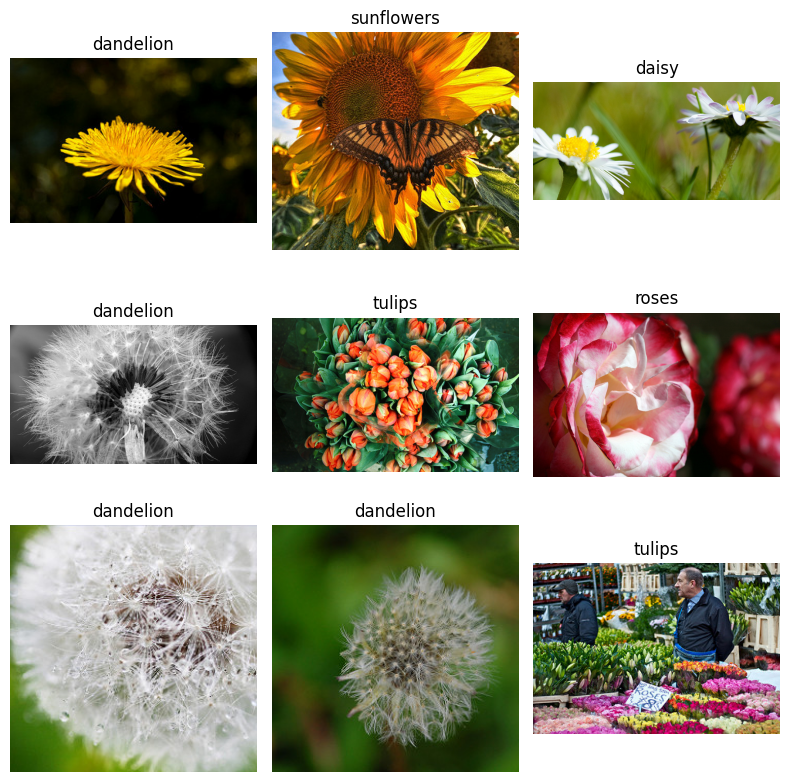

In [13]:
import random
import matplotlib.pyplot as plt

# Pick 9 random images from the training set
plt.figure(figsize=(8, 8))
for i in range(9):
    img, label = train[random.randint(0, len(train) - 1)]
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(train.classes[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

#### Step 3: Customize a dataset
When data isn't arranged in class folders, write your own Dataset class. It needs three methods: `__init__`, `__len__` and `__getitem__`. Here the flower folders are wrapped in a custom class.

In [14]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class FlowerDataset(Dataset):
    # Collect image paths and labels
    def __init__(self, root, transform=None):
        self.transform = transform
        self.classes = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
        self.samples = []
        for idx, cls in enumerate(self.classes):
            folder = os.path.join(root, cls)
            for name in os.listdir(folder):
                self.samples.append((os.path.join(folder, name), idx))

    # Dataset size
    def __len__(self):
        return len(self.samples)

    # Return one (image, label) pair
    def __getitem__(self, index):
        path, label = self.samples[index]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

# Resize every image to the same size and convert to a tensor
transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])

dataset = FlowerDataset("./flower_photos_train", transform=transform)
loader = DataLoader(dataset, batch_size=4, shuffle=True)

# Check one batch
images, labels = next(iter(loader))
print("Dataset size:", len(dataset))
print("Classes:", dataset.classes)
print("Image batch:", images.shape)
print("Label batch:", labels)

Dataset size: 3618
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Image batch: torch.Size([4, 3, 224, 224])
Label batch: tensor([0, 2, 4, 4])


## 1.3 Building a LeNet Network
### Load and preprocess CIFAR-10
CIFAR-10 has 60,000 colour images (32×32) in 10 classes. The images are converted to tensors and normalized to the range -1 to 1.

In [15]:
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

# Convert to tensor, then normalize each RGB channel to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Download and load the training and test sets
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

trainloader = DataLoader(trainset, batch_size=64, shuffle=True)
testloader = DataLoader(testset, batch_size=64, shuffle=False)

# Check sizes and one batch
images, labels = next(iter(trainloader))
print("Train size:", len(trainset), "| Test size:", len(testset))
print("Classes:", trainset.classes)
print("Batch:", images.shape, labels.shape)

100%|██████████| 170M/170M [04:46<00:00, 594kB/s]


Train size: 50000 | Test size: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Batch: torch.Size([64, 3, 32, 32]) torch.Size([64])


### Define the LeNet network
Two convolution layers with pooling extract features, and three fully connected layers classify them into 10 classes.

In [16]:
import torch.nn as nn
import torch.nn.functional as F

class LeNet(nn.Module):
    # Layers
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    # Forward pass
    def forward(self, x):
        x = F.max_pool2d(torch.tanh(self.conv1(x)), 2)
        x = F.max_pool2d(torch.tanh(self.conv2(x)), 2)
        x = x.view(x.size(0), -1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)

# Create the model on the GPU and test it with the batch from the last step
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = LeNet().to(device)
print(net)
print("Output shape:", net(images.to(device)).shape)

LeNet(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)
Output shape: torch.Size([64, 10])


### Train the network
Cross-entropy loss with SGD (learning rate 0.001, momentum 0.9). The average loss of each epoch is recorded so it can be plotted afterwards.

In [17]:
import torch.optim as optim

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

epochs = 20
loss_history = []

# Training loop
for epoch in range(epochs):
    running_loss = 0.0
    for inputs, targets in trainloader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        loss = criterion(net(inputs), targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    avg_loss = running_loss / len(trainloader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}  loss: {avg_loss:.4f}")

Epoch 1/20  loss: 2.1218
Epoch 2/20  loss: 1.9177
Epoch 3/20  loss: 1.7703
Epoch 4/20  loss: 1.6170
Epoch 5/20  loss: 1.4994
Epoch 6/20  loss: 1.4317
Epoch 7/20  loss: 1.3816
Epoch 8/20  loss: 1.3413
Epoch 9/20  loss: 1.3090
Epoch 10/20  loss: 1.2776
Epoch 11/20  loss: 1.2519
Epoch 12/20  loss: 1.2267
Epoch 13/20  loss: 1.2070
Epoch 14/20  loss: 1.1855
Epoch 15/20  loss: 1.1657
Epoch 16/20  loss: 1.1470
Epoch 17/20  loss: 1.1314
Epoch 18/20  loss: 1.1175
Epoch 19/20  loss: 1.1027
Epoch 20/20  loss: 1.0931


### Plot the loss and evaluate the network
The loss curve shows how training progressed, and the test set measures how well the network classifies images it has never seen.

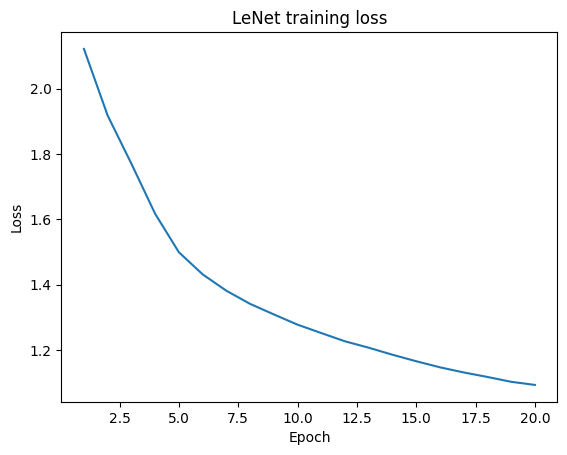

Test accuracy: 59.52%


In [18]:
import matplotlib.pyplot as plt

# Loss curve
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet training loss")
plt.show()

# Test accuracy
correct, total = 0, 0
net.eval()
with torch.no_grad():
    for inputs, targets in testloader:
        inputs, targets = inputs.to(device), targets.to(device)
        predicted = net(inputs).argmax(dim=1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()
print(f"Test accuracy: {100 * correct / total:.2f}%")

## 1.4 Building a ResNet-50 Network
### Configure the experiment and load the data
All settings are kept in one config object. The flower photos are resized to 224×224, randomly flipped for the training set, and normalized.

In [19]:
!pip install easydict

In [20]:
import torch
from easydict import EasyDict as edict
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Experiment settings (the guide's batch_size 1 and cpu are changed for the GPU)
cfg = edict({
    "train_path": "./flower_photos_train",
    "test_path": "./flower_photos_test",
    "batch_size": 32,
    "epoch_size": 5,
    "num_class": 5,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
})

# Preprocessing
normalize = transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
train_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), normalize])
test_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])

# Datasets and loaders
train_data = datasets.ImageFolder(cfg.train_path, transform=train_tf)
test_data = datasets.ImageFolder(cfg.test_path, transform=test_tf)
train_loader = DataLoader(train_data, batch_size=cfg.batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=cfg.batch_size, shuffle=False)

# Check
images, labels = next(iter(train_loader))
print("Device:", cfg.device)
print("Train:", len(train_data), "| Test:", len(test_data))
print("Batch:", images.shape)

Device: cuda
Train: 3618 | Test: 52
Batch: torch.Size([32, 3, 224, 224])


### Define the ResNet-50 network
ResNet-50 is built from bottleneck blocks (1×1, 3×3, 1×1 convolutions) with a shortcut connection that adds the block's input to its output. The stages have [3, 4, 6, 3] blocks.

In [21]:
import torch.nn as nn

# Bottleneck block with shortcut connection
class BottleNeck(nn.Module):
    expansion = 4

    def __init__(self, in_ch, ch, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, ch, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(ch)
        self.conv2 = nn.Conv2d(ch, ch, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(ch)
        self.conv3 = nn.Conv2d(ch, ch * 4, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(ch * 4)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return self.relu(out + identity)

# Full network
class ResNet(nn.Module):
    def __init__(self, block, layers, num_classes):
        super().__init__()
        self.in_ch = 64
        self.conv1 = nn.Conv2d(3, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, 2, 1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512 * block.expansion, num_classes)

    # Stack blocks; the first one may change size/channels
    def _make_layer(self, block, ch, blocks, stride=1):
        downsample = None
        if stride != 1 or self.in_ch != ch * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_ch, ch * block.expansion, 1, stride, bias=False),
                nn.BatchNorm2d(ch * block.expansion))
        layers = [block(self.in_ch, ch, stride, downsample)]
        self.in_ch = ch * block.expansion
        layers += [block(self.in_ch, ch) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        return self.fc(x)

def resnet50(num_classes):
    return ResNet(BottleNeck, [3, 4, 6, 3], num_classes)

# Create the model and test it with the batch from the last step
model = resnet50(cfg.num_class).to(cfg.device)
print("Output shape:", model(images.to(cfg.device)).shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Output shape: torch.Size([32, 5])
Parameters: 23518277


### Train the ResNet-50 network
SGD with momentum and weight decay, and a scheduler that lowers the learning rate when the loss stops improving. The trained weights are saved at the end.

In [22]:
import torch.optim as optim

# Loss, optimizer and learning-rate scheduler
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=0.0001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)

# Training loop
resnet_loss = []
for epoch in range(cfg.epoch_size):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(cfg.device), targets.to(cfg.device)
        optimizer.zero_grad()
        loss = criterion(model(inputs), targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    avg_loss = running_loss / len(train_loader)
    scheduler.step(avg_loss)
    resnet_loss.append(avg_loss)
    print(f"Epoch {epoch + 1}/{cfg.epoch_size}  loss: {avg_loss:.4f}")

# Save the trained weights
torch.save(model.state_dict(), "resnet50_flowers.pth")
print("Saved resnet50_flowers.pth")

Epoch 1/5  loss: 2.5121
Epoch 2/5  loss: 1.4524
Epoch 3/5  loss: 1.3289
Epoch 4/5  loss: 1.2072
Epoch 5/5  loss: 1.1796
Saved resnet50_flowers.pth


### Test the ResNet-50 network
The trained network classifies the test images, and the accuracy is calculated. A few predictions are also shown next to the true labels.

In [23]:
# Test accuracy
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(cfg.device), targets.to(cfg.device)
        predicted = model(inputs).argmax(dim=1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()
print(f"Test accuracy: {100 * correct / total:.2f}% ({correct}/{total})")

# Show predictions for the first test batch
inputs, targets = next(iter(test_loader))
predicted = model(inputs.to(cfg.device)).argmax(dim=1).cpu()
print("True:     ", [test_data.classes[t] for t in targets[:8]])
print("Predicted:", [test_data.classes[p] for p in predicted[:8]])

Test accuracy: 57.69% (30/52)
True:      ['daisy', 'daisy', 'daisy', 'daisy', 'daisy', 'daisy', 'daisy', 'daisy']
Predicted: ['sunflowers', 'daisy', 'daisy', 'daisy', 'daisy', 'tulips', 'daisy', 'daisy']


## 1.5 Building a TextCNN Network
### Download and read the IMDB dataset
The IMDB dataset has 50,000 movie reviews labelled positive (1) or negative (0), split into 25,000 for training and 25,000 for testing.

In [24]:
!wget -q https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
!tar -xzf aclImdb_v1.tar.gz
!ls aclImdb

imdbEr.txt  imdb.vocab	README	test  train


In [25]:
import os

# Read every review of one split into a list of texts and a list of labels
def read_imdb(split):
    texts, labels = [], []
    for label, name in enumerate(["neg", "pos"]):
        folder = os.path.join("aclImdb", split, name)
        for file in os.listdir(folder):
            with open(os.path.join(folder, file), encoding="utf-8") as f:
                texts.append(f.read())
            labels.append(label)
    return texts, labels

train_texts, train_labels = read_imdb("train")
test_texts, test_labels = read_imdb("test")

# Check
print("Train:", len(train_texts), "| Test:", len(test_texts))
print("Positive reviews in train:", sum(train_labels))
print("Sample label:", train_labels[0])
print("Sample review:", train_texts[0][:200])

Train: 25000 | Test: 25000
Positive reviews in train: 12500
Sample label: 0
Sample review: Much worse than the original. It was actually *painful* to sit through, and it barely held my six year old's interest.<br /><br />Introduction of some new Pokemon is marginally interesting, but storyl


### Preprocess the text
Reviews are lowercased, stripped of HTML tags and punctuation, and split into words. The 10,000 most frequent words form the vocabulary, each word is replaced by its index, and every review is padded or cut to exactly 200 words.

In [26]:
import re
import torch
from collections import Counter

# Clean one review and split it into words
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-z\s]", "", text)
    return text.split()

# Vocabulary of the most frequent training words (0 = padding, 1 = unknown)
def build_vocab(tokenized_texts, size=10000):
    counter = Counter(word for tokens in tokenized_texts for word in tokens)
    vocab = {"<pad>": 0, "<unk>": 1}
    for word, _ in counter.most_common(size):
        vocab[word] = len(vocab)
    return vocab

# Words to indices
def text_to_sequence(tokens, vocab):
    return [vocab.get(word, 1) for word in tokens]

# Cut long reviews and pad short ones to a fixed length
def pad_sequence(seq, max_len=200):
    return seq[:max_len] + [0] * (max_len - len(seq))

# Apply to both splits
train_tokens = [preprocess_text(t) for t in train_texts]
test_tokens = [preprocess_text(t) for t in test_texts]
vocab = build_vocab(train_tokens)

X_train = torch.tensor([pad_sequence(text_to_sequence(t, vocab)) for t in train_tokens])
X_test = torch.tensor([pad_sequence(text_to_sequence(t, vocab)) for t in test_tokens])
y_train = torch.tensor(train_labels)
y_test = torch.tensor(test_labels)

# Check
print("Vocabulary size:", len(vocab))
print("First words:", train_tokens[0][:10])
print("First indices:", X_train[0][:10].tolist())
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Vocabulary size: 10002
First words: ['much', 'worse', 'than', 'the', 'original', 'it', 'was', 'actually', 'painful', 'to']
First indices: [72, 428, 70, 2, 198, 9, 13, 157, 1286, 6]
X_train: torch.Size([25000, 200]) | X_test: torch.Size([25000, 200])


### Define the TextCNN network
Each word index is turned into a 128-number embedding. Three convolution filters of widths 3, 4 and 5 (100 each) scan the review like n-gram detectors, max pooling keeps each filter's strongest signal, and a final layer outputs negative or positive.

In [27]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Dataset wrapper
class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

# Loaders
text_train_loader = DataLoader(IMDBDataset(X_train, y_train), batch_size=64, shuffle=True)
text_test_loader = DataLoader(IMDBDataset(X_test, y_test), batch_size=64, shuffle=False)

# TextCNN
class TextCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, kernel_sizes=(3, 4, 5), num_filters=100, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embed_dim, num_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, x):
        x = self.embedding(x).permute(0, 2, 1)
        pooled = [F.relu(conv(x)).max(dim=2).values for conv in self.convs]
        return self.fc(self.dropout(torch.cat(pooled, dim=1)))

# Create the model and test it with one batch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
text_model = TextCNN(len(vocab)).to(device)
batch_x, batch_y = next(iter(text_train_loader))
print("Output shape:", text_model(batch_x.to(device)).shape)
print("Parameters:", sum(p.numel() for p in text_model.parameters()))

Output shape: torch.Size([64, 2])
Parameters: 1434758


### Train the TextCNN network
Adam optimizer (learning rate 0.001) with cross-entropy loss, for 10 epochs.

In [28]:
import torch.optim as optim

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(text_model.parameters(), lr=0.001)

# Training loop
text_epochs = 10
text_loss = []
for epoch in range(text_epochs):
    text_model.train()
    running_loss = 0.0
    for inputs, targets in text_train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        loss = criterion(text_model(inputs), targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    avg_loss = running_loss / len(text_train_loader)
    text_loss.append(avg_loss)
    print(f"Epoch {epoch + 1}/{text_epochs}  loss: {avg_loss:.4f}")

Epoch 1/10  loss: 0.6426
Epoch 2/10  loss: 0.4862
Epoch 3/10  loss: 0.4157
Epoch 4/10  loss: 0.3556
Epoch 5/10  loss: 0.2910
Epoch 6/10  loss: 0.2425
Epoch 7/10  loss: 0.1959
Epoch 8/10  loss: 0.1556
Epoch 9/10  loss: 0.1235
Epoch 10/10  loss: 0.0940


### Test the TextCNN network and predict sentiment
The test set measures accuracy on reviews the model has never seen, and a prediction function classifies any sentence you type.

In [29]:
# Test accuracy
text_model.eval()
correct, total = 0, 0
with torch.no_grad():
    for inputs, targets in text_test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        predicted = text_model(inputs).argmax(dim=1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()
print(f"Test accuracy: {100 * correct / total:.2f}%")

# Predict the sentiment of a single sentence
def predict_sentiment(sentence):
    seq = pad_sequence(text_to_sequence(preprocess_text(sentence), vocab))
    with torch.no_grad():
        probs = torch.softmax(text_model(torch.tensor([seq]).to(device)), dim=1)[0]
    label = "Positive" if probs[1] > probs[0] else "Negative"
    return f"{label} ({probs.max().item():.2%})"

print(predict_sentiment("This movie was fantastic, I loved every minute of it"))
print(predict_sentiment("This was a terrible film and a complete waste of time"))

Test accuracy: 84.28%
Positive (99.54%)
Negative (99.83%)


## 1.6 Questions

### Question 1
**Why does the loss not decrease but increase during LeNet and ResNet training?**

**Answer:** A rising loss usually means that training has become unstable. The common causes are:
- **Learning rate too high.** The optimizer takes steps that overshoot the minimum, so the loss bounces around or grows, and can even reach `nan`. This is the most common cause. In this lab, the guide's ResNet learning rate of 0.1 is too high for a batch size of 32, so I used 0.01.
- **Momentum or weight decay set too aggressively**, which can amplify the overshooting.
- **Unnormalized inputs or a poor weight initialization**, which make the gradients very large.
- **Wrong loss, labels or data pipeline**, for example labels that do not match the images, or the optimizer's gradients not being cleared with `zero_grad()`.
- **A batch size that is too small** (the guide uses 1 for ResNet), which makes each gradient update very noisy.

The fix is to lower the learning rate, use a larger batch size, normalize the inputs, and check that the labels and the training loop are correct.

### Question 2
**Can the accuracy be further improved if we continue to increase the number of training epochs during CIFAR-10 training of LeNet? If it can or cannot, why?**

**Answer:** Only up to a point. In this lab, LeNet trained for 20 epochs reached 59.52% test accuracy, and its loss was still falling slowly, so more epochs would help at first. After that, the accuracy stops improving, for two reasons:
- **Limited capacity.** LeNet is a very small network (two convolution layers and three fully connected layers), so it cannot learn all the features needed to separate CIFAR-10's colour images. Its accuracy has a ceiling that more training cannot raise.
- **Overfitting.** Once the network starts to memorize the training images, the training loss keeps falling while the test accuracy stalls or drops.

To go beyond this ceiling, a deeper network (such as ResNet) is needed.

### Question 3
**How can we further improve network accuracy without changing the network structure?**

**Answer:** The accuracy can be improved through the data, the training settings and regularization, without touching the layers:
- **Data augmentation.** Random flips, crops, rotations and colour changes give the network more varied examples, which reduces overfitting.
- **More training data**, if it is available.
- **Tuning the hyperparameters.** Adjust the learning rate (with a decay schedule), the batch size, the optimizer (for example Adam instead of SGD) and the number of epochs.
- **Regularization.** Use weight decay, dropout, and early stopping.
- **Better preprocessing.** Normalize the inputs properly and make sure the images are a suitable size.
- **Transfer learning.** Start from pretrained weights instead of random ones, which helps a lot with small datasets like the flower photos.
- **Ensembling.** Average the predictions of several trained models.